# 06 · Forecast combination and anchoring to the forward curve

Notebook 05 left two facts. AR(1) measurement errors fix the one-month
forecasts. At 6–12 months nothing beats forwards or the random walk, and
README §7.6 (failure 4) puts that down to the forward curve knowing the
expected policy path. This notebook tests the next two items of README §8
step 7b, both aimed at that horizon:

3. **Forecast combination.** Average the model with the forecasts it
   competes against. Models fail in different periods, and averages hold up
   over time in the term-structure literature (de Pooter, Ravazzolo & van
   Dijk 2010).
   - **Set A:** yields + AR(1) errors, two-step VAR(1), forwards and the
     random walk.
   - **Set B:** set A plus yields + policy rate + AR(1).
   - **Weights:** equal, or inverse past MSE (Bates & Granger 1969).
     Inverse-MSE weights are set per maturity and horizon, from errors
     already realised at the origin only, with equal weights until each
     model has 24 of them (`yck.eval.combine`).
4. **Anchoring the short end to forwards.** Tilt the model's Gaussian
   forecast of the curve so the 3m–12m means equal the forward rates
   (Altavilla, Giacomini & Ragusa 2017). The rest of the curve moves by its
   forecast covariance with the short end: μ* = μ + Σ·s Σss⁻¹(F − μs), with
   Σ = Λ P_{t+h|t} Λ' + H from the model (`yck.model.adjust.anchor_mean`).
   It is applied to yields only and policy rate only, each plain and with
   AR(1) errors. The literature tilts to surveys; tilting to forwards is
   untested.

**The grid was fixed and committed before anything was run** (README §8 step
7b, commit `328364e`). Everything in it is reported below.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

from yck.model.dns import maturities_from_columns
from yck.eval.backtest import dns_two_step_forecasts, random_walk_forecasts, forward_forecasts
from yck.eval.combine import combine
from yck.eval.grid import (STANDARD_GRID, BACKTEST_DEFAULTS, COMBINATION_SETS, accuracy_grid, anchor_grid,
                           combination_forecasts, ensure_results, tag_of, _grid_for)
from yck.eval.stats import dm_table, mcs_table

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RESULTS, CONFIG, DATA = ROOT / "data/results", ROOT / "config/data_sources.yaml", ROOT / "data"
CCYS = ["USD", "EUR", "GBP"]
H = (1, 6, 12)
SHOW = {"USD": ["3m", "12m", "24m", "60m", "120m"], "EUR": ["3m", "12m", "24m", "60m", "120m"],
        "GBP": ["6m", "12m", "24m", "60m", "120m"]}
FIRST_ORIGIN = {c: BACKTEST_DEFAULTS[c][1] for c in CCYS}
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
CAP = [{"selector": "caption", "props": "font-weight: bold; text-align: left"}]

for g in (STANDARD_GRID, accuracy_grid, anchor_grid):  # one grid run if anything is missing
    ensure_results(CCYS, DATA, CONFIG, grid=g)

def name_of(row):
    m, lam, tau, ep, err, anc, *_ = tuple(row) + (None,) * (9 - len(row))
    base = ("policy rate" if m == ("policy_rate",) else "full macro" if m else "yields")
    base += "" if lam == "fixed" else ", λ est."
    base += f", shrink {tau:g}" if tau is not None else ""
    base += f", endpoint {ep}" if ep else ""
    base += " + AR(1)" if err == "ar1" else " + AR(1) with mean" if err == "ar1c" else ""
    return base + (", anchored" if anc else "")

y, fc = {}, {}
for c in CCYS:
    est = BACKTEST_DEFAULTS[c][0]
    full = pd.read_parquet(ROOT / f"data/processed/curves_{c}.parquet")
    y[c] = full.loc[est:] if est else full
    fc[c] = {}
    for g in (STANDARD_GRID, accuracy_grid, anchor_grid):
        for r in _grid_for(g, c):
            fc[c][name_of(r)] = {h: pd.read_parquet(RESULTS / f"fc_{c}_kalman_{tag_of(r)}_h{h}.parquet") for h in H}
    fc[c]["two-step AR(1)"] = dns_two_step_forecasts(y[c], H, FIRST_ORIGIN[c])
    fc[c]["two-step VAR(1)"] = dns_two_step_forecasts(y[c], H, FIRST_ORIGIN[c], kind="var1")
    fc[c]["random walk"] = random_walk_forecasts(y[c], H, FIRST_ORIGIN[c])
    fc[c]["forwards"] = forward_forecasts(pd.read_parquet(ROOT / f"data/processed/curves_ext_{c}.parquet"),
                                          y[c].columns, H, FIRST_ORIGIN[c])
    fc[c].update(combination_forecasts(c, DATA, CONFIG, sets=("A", "B")))
ANCHORED = [name_of(r) for r in _grid_for(anchor_grid, "USD")]
UNANCHORED = [name_of(r[:5]) for r in _grid_for(anchor_grid, "USD")]
COMBOS = [n for n in fc["USD"] if n.startswith("combination")]
pd.DataFrame({c: {"models compared": len(fc[c])} for c in CCYS})

,USD,EUR,GBP
models compared,42,36,30


## 1. What anchoring does to one forecast

The EUR 12-month forecast made in January 2015, when the ECB was about to
start buying bonds. The plain model forecast a rebound towards its mean.
The forwards priced rates near zero for a long time. The anchored forecast
takes the forwards at 3m–12m and lets the model carry them out along the
curve.

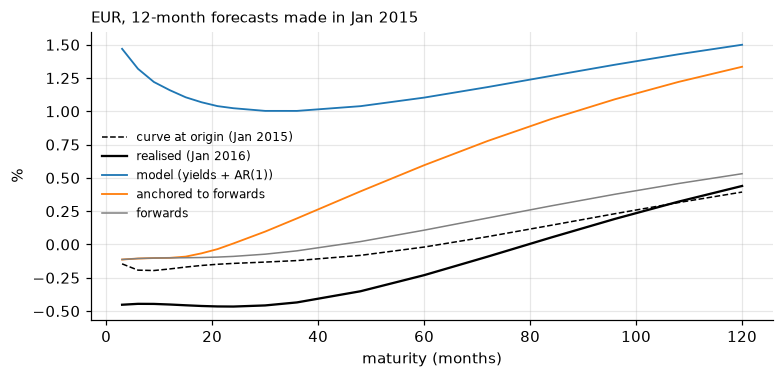

In [2]:
c, origin, h = "EUR", pd.Timestamp("2015-01-31"), 12
target = origin + pd.offsets.MonthEnd(h)
tau = maturities_from_columns(y[c].columns)
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(tau, y[c].loc[origin], "k--", lw=1, label=f"curve at origin ({origin:%b %Y})")
ax.plot(tau, y[c].loc[target], "k", lw=1.5, label=f"realised ({target:%b %Y})")
ax.plot(tau, fc[c]["yields + AR(1)"][h].loc[target], lw=1.2, label="model (yields + AR(1))")
ax.plot(tau, fc[c]["yields + AR(1), anchored"][h].loc[target], lw=1.2, label="anchored to forwards")
ax.plot(tau, fc[c]["forwards"][h].loc[target], lw=1, color="0.5", label="forwards")
ax.set_xlabel("maturity (months)"); ax.set_ylabel("%"); ax.legend(fontsize=8, frameon=False)
ax.set_title(f"EUR, 12-month forecasts made in {origin:%b %Y}", loc="left", fontsize=10);

## 2. Anchoring: every variant against forwards, the random walk and itself

Cells are RMSE ratios. Against forwards and against the unanchored model
they carry Diebold–Mariano stars in either direction (* 10%, ** 5%, *** 1%).
Below 1 means the anchored model wins. At the anchored maturities the
forecast equals the forward rate, so the forward ratio there is 1 by
construction (up to GBP months where a forward is missing).

In [3]:
def after(c, h):
    return y[c].loc[pd.Timestamp(FIRST_ORIGIN[c]) + pd.offsets.MonthEnd(h):]

def vs(c, bench, h, names, field="cell"):
    t = dm_table({n: fc[c][n][h] for n in [bench] + names}, bench, after(c, h), h, SHOW[c])
    return t.xs(field, axis=1, level=1).T

for c in CCYS:
    rows = {}
    for a, u in zip(ANCHORED, UNANCHORED):
        for h in H:
            rows[(a, f"h = {h}", "÷ forwards")] = vs(c, "forwards", h, [a]).loc[a]
            rows[(a, f"h = {h}", "÷ unanchored")] = vs(c, u, h, [a]).loc[a]
            rows[(a, f"h = {h}", "÷ random walk")] = vs(c, "random walk", h, [a], "ratio").loc[a].astype(float).round(2)
    display(pd.DataFrame(rows).T.style.set_caption(f"{c}: anchored models").set_table_styles(CAP))

## 3. Combinations against forwards and the random walk

RMSE / forwards with Diebold–Mariano stars, and RMSE / random walk (ratio
only).

In [4]:
for c in CCYS:
    t = pd.concat({**{f"÷ forwards, h = {h}": vs(c, "forwards", h, COMBOS) for h in H},
                   **{f"÷ RW, h = {h}": vs(c, "random walk", h, COMBOS, "ratio").astype(float).round(2) for h in H}},
                  axis=1)
    display(t.style.set_caption(f"{c}: combinations").set_table_styles(CAP))

### Where the inverse-MSE weights go

Set A's real-time weights for the 10-year yield at h = 12. They move slowly,
because the window expands. The dotted line marks the switch from equal
weights, once every forecast has 24 realised errors.

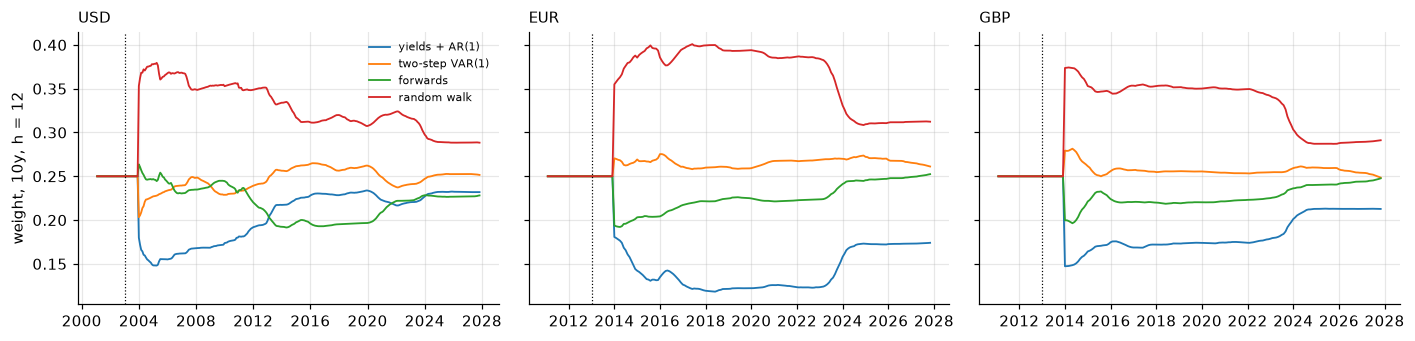

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2), sharey=True)
for ax, c in zip(axes, CCYS):
    comp = {"yields + AR(1)": fc[c]["yields + AR(1)"][12], "two-step VAR(1)": fc[c]["two-step VAR(1)"][12],
            "forwards": fc[c]["forwards"][12], "random walk": fc[c]["random walk"][12]}
    _, w = combine(comp, y[c], 12, "inv_mse", return_weights=True)
    for n, wn in w.items():
        ax.plot(wn["120m"].loc[FIRST_ORIGIN[c]:], lw=1.2, label=n)
    ax.axvline(pd.Timestamp(FIRST_ORIGIN[c]) + pd.offsets.MonthEnd(12 + 24 - 1), ls=":", color="k", lw=0.8)
    ax.set_title(c, loc="left", fontsize=10)
axes[0].set_ylabel("weight, 10y, h = 12"); axes[0].legend(fontsize=7, frameon=False); fig.tight_layout()

## 4. Model confidence set over everything

The 90% model confidence set (Hansen, Lunde & Nason 2011) over every model
in notebooks 02–06: the step 7 grid, the step 7b grid (endpoints, error
models, anchoring), the combinations, the two-step models, the random walk
and forwards. The first table counts the models in the set out of those
compared. The second gives the MCS p-values for the pooled loss over
maturities: a model is in the set when p ≥ 0.10.

In [6]:
SHORT = "3m / 6m (GBP)"
mcs = {(c, h): mcs_table({n: f[h] for n, f in fc[c].items()}, after(c, h), h, SHOW[c], n_boot=2000)
               .rename(columns={SHOW[c][0]: SHORT})
       for c in CCYS for h in H}
summary = {(c, f"h = {h}"): {col: f"{int((t[col] >= 0.10).sum())} / {int(t[col].notna().sum())}" for col in t.columns}
           for (c, h), t in mcs.items()}
display(pd.DataFrame(summary).T.style.set_caption("Models in the 90% MCS / models compared").set_table_styles(CAP))
KEY = ["yields", "yields + AR(1)", "policy rate + AR(1)", "yields + AR(1), anchored",
       "policy rate + AR(1), anchored"] + COMBOS + ["two-step VAR(1)", "random walk", "forwards"]
pd.DataFrame({(c, f"h = {h}"): mcs[(c, h)].loc[KEY, "all"] for c in CCYS for h in H}).round(2)

USD                EUR                GBP  \
                              h = 1 h = 6 h = 12 h = 1 h = 6 h = 12 h = 1   
model                                                                       
yields                         0.01  0.95   0.99  0.00  0.51   0.49  0.01   
yields + AR(1)                 0.64  0.96   0.99  0.09  0.42   0.49  0.78   
policy rate + AR(1)            0.81  0.96   0.99  0.09  0.31   0.23  0.78   
yields + AR(1), anchored       0.73  0.89   0.96  0.85  0.93   0.78  0.78   
policy rate + AR(1), anchored  0.80  0.89   0.99  0.85  0.93   0.79  0.78   
combination A, equal           0.94  0.96   0.99  0.12  0.51   0.49  0.78   
combination A, inverse MSE     0.98  0.96   0.99  0.85  0.93   0.78  0.78   
combination B, equal           0.98  0.96   1.00  0.12  0.51   0.49  0.78   
combination B, inverse MSE     1.00  1.00   0.99  0.12  0.51   0.49  0.78   
two-step VAR(1)                0.17  0.96   0.99  0.12  0.51   0.49  0.05   
random walk                    0.57  0.96   0.99  0.85  0.93   0.95  1.00   
forwards                       0.98  0.96   0.99  1.00  1.00   1.00   NaN   

                                            
                              h = 6 h = 12  
model                                       
yields                         0.85   0.83  
yields + AR(1)                 0.72   0.83  
policy rate + AR(1)            0.72   0.83  
yields + AR(1), anchored       0.85   0.73  
policy rate + AR(1), anchored  0.85   0.79  
combination A, equal           1.00   0.89  
combination A, inverse MSE     0.98   0.83  
combination B, equal           0.99   0.83  
combination B, inverse MSE     0.90   0.83  
two-step VAR(1)                0.85   0.89  
random walk                    0.99   1.00  
forwards                       0.90   0.83

In [7]:
# Lowest pooled MSE at each horizon on the MCS's common sample, and ranks among all models compared
rows = {}
for (c, h), t in mcs.items():
    a = after(c, h)[SHOW[c]]
    pooled = pd.DataFrame({n: ((f[h].reindex(a.index)[SHOW[c]] - a) ** 2).mean(axis=1, skipna=False)
                           for n, f in fc[c].items()})
    L = pooled.dropna(axis=1, how="all").dropna().mean()
    best = L.idxmin()
    rows[(c, f"h = {h}")] = {"lowest pooled MSE": best,
                             "rank of forwards": int(L.rank()["forwards"]) if "forwards" in L else "–",
                             "rank of random walk": int(L.rank()["random walk"]),
                             "rank of best combination": int(L.rank()[COMBOS].min()),
                             "models": len(L)}
pd.DataFrame(rows).T

lowest pooled MSE rank of forwards rank of random walk  \
USD h = 1   combination B, inverse MSE                4                  15   
    h = 6   combination B, inverse MSE                9                  17   
    h = 12        combination B, equal                9                  10   
EUR h = 1                     forwards                1                   5   
    h = 6                     forwards                1                   7   
    h = 12                    forwards                1                   2   
GBP h = 1                  random walk                –                   1   
    h = 6         combination A, equal                6                   4   
    h = 12                 random walk               11                   1   

           rank of best combination models  
USD h = 1                         1     42  
    h = 6                         1     42  
    h = 12                        1     42  
EUR h = 1                         3     36  
    h = 6                         4     36  
    h = 12                        6     36  
GBP h = 1                         2     29  
    h = 6                         1     30  
    h = 12                        3     30

## 5. Takeaways

1. **Anchoring makes the short end match forwards, but leaves the long end
   to the model.**
   - **EUR is fixed at the short end.** Against the same model unanchored,
     at h = 6–12 (most of these significant):

     | Maturity | Ratio to unanchored | Change |
     |---|---|---|
     | 3m | 0.54–0.70 | −30 to −46% |
     | 1–2y | 0.69–0.77 | −23 to −31% |
     | 5y | 0.82–0.92 | −8 to −18% |

     The EUR short end moves from 1.4–1.9 × forwards to parity.
   - **The EUR long end still loses to forwards** at h = 6–12: 5y 1.04–1.16,
     10y 1.01–1.10.
   - **The tilt barely reaches the 10y.** In the January 2015 example the
     3m forecast moves by 158 bp but the 10y only by 17 bp. The gap at the
     short end is absorbed mostly by the slope and curvature factors, not
     the level.
   - **In USD and GBP the model's short end was already level with
     forwards**, so the tilt adds little there. It makes the long end
     worse:
     - USD 10y at h = 12: 1.08–1.10 × the unanchored model (not
       significant);
     - GBP 10y at h = 12: 1.11–1.13 × forwards (significant at 1–5%).
   - **Literature not reproduced.** Altavilla et al.'s gains (up to 52%)
     come from tilting to surveys. Tilting to forwards cannot beat forwards
     at the maturities it is tied to, and does not beat them further out.
2. **Combination is the first variant at or below forwards at the long end
   in every currency, but it still loses to the random walk there.**
   - **10y at h = 12, against forwards:**

     | | 10y ÷ forwards |
     |---|---|
     | USD | 0.93–0.94 |
     | EUR | 0.97–1.02 |
     | GBP | 0.98–1.00 |

     USD 5y is at 0.95–0.96.
   - **Two results are significant:** EUR 10y at h = 1 (0.98**) and GBP 5y
     at h = 6 (0.96*), both for set A.
   - **Against the random walk** the combinations win at the short end
     (USD 3m 0.84–0.89) but lose at the 10y, h = 12: USD 1.05, EUR
     1.08–1.13, GBP 1.06–1.08.
   - **Inverse-MSE weights beat equal weights in EUR**, where the model is
     bad and its weight falls (3m at h = 1: 1.12 against 1.23 × forwards).
     Elsewhere they are about the same.
   - **Adding the policy-rate model (set B) helps nowhere** and hurts in
     EUR.
3. **Ranking every model (42 USD, 36 EUR, 30 GBP) on pooled squared
   error:**
   - **USD:** a combination is first at every horizon. Forwards rank 4th–9th,
     the random walk 10th–17th.
   - **EUR:** forwards are first at every horizon.
   - **GBP:** the random walk is first at h = 1 and 12, and combination A at
     h = 6.
   - **The confidence set** still cannot separate the models at h = 6–12: it
     keeps 28–42 of 30–42. At h = 1 it drops the plain models
     (p ≤ 0.01). In EUR it also drops the unanchored AR(1) models
     (p = 0.09) but keeps their anchored versions (0.85).
4. **Step 7b items 1–4 in one line.** A model with AR(1) errors, averaged
   with forwards, the random walk and the two-step VAR, is roughly as good as
   the best benchmark in each currency, and better than forwards at the USD
   long end. No variant significantly beats the market at 6–12 months.
5. **What carries forward to the trading evaluation (step 8).**
   - **Combination A with inverse-MSE weights** is never far from the best,
     and is the natural forecast to trade on.
   - **The plain yields + AR(1) model** is kept alongside, as the "pure
     model" signal.
   - **Anchoring is not adopted.** By construction it gives no signal at the
     short end against forwards, and it hurts the long end outside EUR.